<a href="https://colab.research.google.com/github/Erilocshada/erilocshada-machine-learning-course/blob/main/JS_15_244107020064_Muhammad_Pearl_Ocshada.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://colab.research.google.com/github/Erilocshada/erilocshada-machine-learning-course/blob/main/JS_15_244107020064_Muhammad_Pearl_Ocshada.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# JS15 - Pipeline Machine Learning & Deployment
**Muhammad Pearl Ocshada — 244107020064 — JTI Polinema — Modul Praktikum Pembelajaran Mesin 2025/2026**

Cakupan: **Praktikum 1** (membangun & mengekspor model) dan **Praktikum 2** (deployment Flask + Docker ke
Hugging Face Spaces). *Bagian Tugas (deployment ke proyek pribadi) tidak dikerjakan pada notebook ini.*

## 0. Konsep yang dipakai

**Pipeline ML** = rangkaian langkah sistematis yang mengubah data mentah menjadi keputusan/prediksi.

| Tahap | Yang dilakukan di modul ini | Artefak |
|---|---|---|
| A. Data ingestion | baca gambar dari folder `training/` & `test/` (subfolder `day`, `night`) | list `(gambar, label)` |
| B. Preprocessing | `cv2.resize` 256×256 + konversi grayscale | matriks gambar seragam |
| C. Feature extraction | HOG (`orientations=9`, `pixels_per_cell=(8,8)`, `cells_per_block=(2,2)`, `block_norm='L2-Hys'`) lalu `StandardScaler` | vektor fitur + **`scaler.pkl`** |
| D. Modeling | Neural Network feedforward 128 → 64 → 1(sigmoid), Adam + `binary_crossentropy` | **`day_night_model.h5`** |

**Kenapa `scaler` wajib disimpan?** Normalisasi memakai mean & standar deviasi yang *dipelajari dari data
training*. Saat inference, data harus diperlakukan **persis sama**; kalau scaler dibuang (atau di-`fit` ulang
pada data test), distribusi fitur bergeser dan prediksi menjadi tidak valid.

**Kenapa deployment butuh Docker?** Mencegah *dependency hell* (versi TensorFlow/library berbeda antara
laptop dan server) dan menjamin *portability*: image yang dibangun di laptop berperilaku sama di Hugging Face,
Cloud Run, atau AWS ECS. Peran ketiganya: **Flask** = resepsionis (terima request → panggil model → balas hasil),
**Docker** = rumah/wadah (menyiapkan Python, OpenCV, TensorFlow), **Hugging Face Spaces** = tanah (server + akses
internet).

---
# Praktikum 1 — Membangun & Ekspor Model (Day vs Night)

## Langkah 1: Import Library dan Mount Google Drive

In [ ]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt
import cv2

from skimage.feature import hog
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

import tensorflow as tf
from tensorflow.keras import layers, models

IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')

print('OpenCV       :', cv2.__version__)
print('TensorFlow   :', tf.__version__)
print('Menjalankan di Colab:', IN_COLAB)

OpenCV       : 5.0.0
TensorFlow   : 2.20.0
Menjalankan di Colab: False


## Langkah 2: Load Dataset

Dataset `images.zip` dari modul berisi 400 gambar: 240 data training (`day` 120, `night` 120) dan
160 data testing (`day` 80, `night` 80). Label diambil dari nama subfolder.

In [ ]:
def find_data_dir():
    """Cari folder dataset baik saat dijalankan di Colab (Google Drive) maupun lokal (repo)."""
    candidates = [
        Path('/content/drive/MyDrive/ML/data/images'),
        Path('/content/drive/MyDrive/ML/data/images/images'),
        Path.cwd() / 'data' / 'images',
        Path.cwd() / 'data' / 'images' / 'images',
    ]
    for c in candidates:
        if (c / 'training').is_dir():
            return c
    raise FileNotFoundError('Folder images/training tidak ditemukan. Sesuaikan path dataset.')

DATA_DIR = find_data_dir()
train_dir = str(DATA_DIR / 'training') + '/'
test_dir  = str(DATA_DIR / 'test') + '/'
print('Dataset root :', DATA_DIR)


# Load images and labels from a directory structure
def load_dataset(img_dir):
    p = Path(img_dir)
    img_list = []
    for folder in sorted(p.glob('*')):
        label = folder.name
        for file in sorted(folder.glob('*.jpg')):
            img = cv2.imread(str(file))
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            img_list.append((img, label))
    return img_list

train_img = load_dataset(train_dir)
test_img  = load_dataset(test_dir)

print(f"Jumlah data training: {len(train_img)}")
print(f"Jumlah data testing : {len(test_img)}")

Dataset root : D:\KULIAH\SMT-5\Machine Learning\erilocshada-machine-learning-course\data\images\images


Jumlah data training: 240
Jumlah data testing : 160


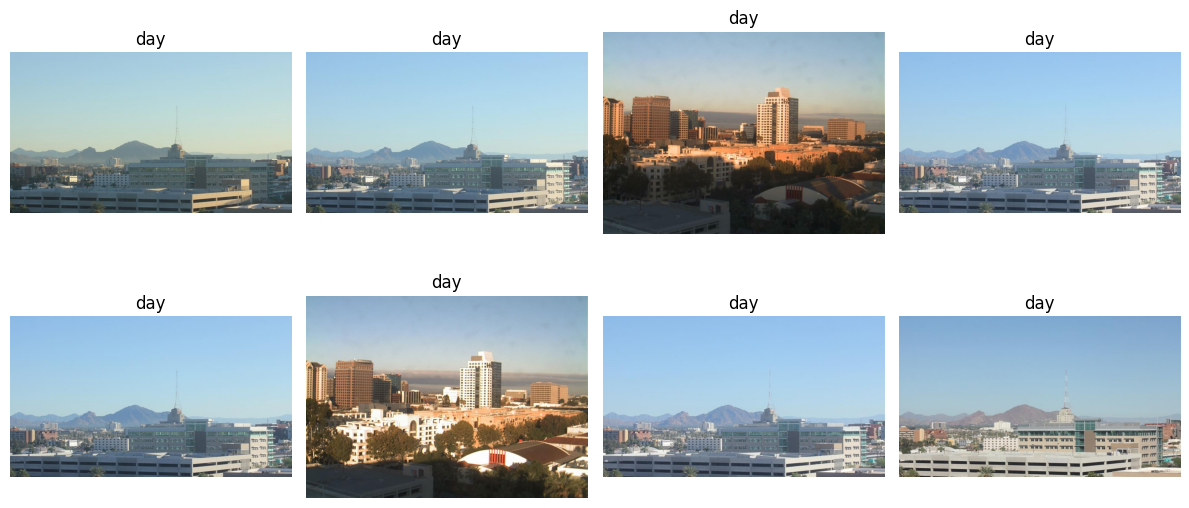

In [ ]:
# Cuplikan beberapa gambar beserta labelnya
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for ax, (img, label) in zip(axes.ravel(), train_img[:4] + test_img[:4]):
    ax.imshow(img)
    ax.set_title(label)
    ax.axis('off')
plt.tight_layout(); plt.show()

## Langkah 3: Preprocessing (Resize & Label Encoding)

Gambar diseragamkan ke **256×256** karena model memerlukan vektor input dengan dimensi konsisten,
dan label teks diubah menjadi angka biner (`day` → 1, `night` → 0).

In [ ]:
# Preprocess images: resize and encode labels
def resize_image(img, size=(256, 256)):
    return cv2.resize(img, size)

def label_encoder(label):
    return 1 if label == 'day' else 0

def preprocess(img_list):
    X, y = [], []
    for img, label in img_list:
        X.append(resize_image(img))
        y.append(label_encoder(label))
    return X, y

X_train_img, y_train = preprocess(train_img)
X_test_img,  y_test  = preprocess(test_img)

print('Ukuran gambar seragam :', X_train_img[0].shape)
print('Distribusi label train (0=night, 1=day):', np.bincount(y_train))
print('Distribusi label test  (0=night, 1=day):', np.bincount(y_test))

Ukuran gambar seragam : (256, 256, 3)
Distribusi label train (0=night, 1=day): [120 120]
Distribusi label test  (0=night, 1=day): [80 80]


## Langkah 4: Ekstraksi Fitur HOG (Histogram of Oriented Gradients)

Komputer tidak "melihat" gambar seperti manusia — ia melihat angka. HOG mengubah pikar mentah menjadi
deskriptor **bentuk dan tepi** dengan menghitung arah gradien cahaya per sel (8×8 piksel) yang
dikelompokkan per blok (2×2), lalu dinormalisasi dengan skema `L2-Hys` sehingga tidak sensitif
terhadap perubahan pencahayaan — cocok untuk membedakan siang vs malam.

In [ ]:
# Extract HOG features
def extract_hog(X_imgs):
    feats = []
    for img in X_imgs:
        gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
        hog_feat = hog(gray,
                       orientations=9,
                       pixels_per_cell=(8, 8),
                       cells_per_block=(2, 2),
                       block_norm='L2-Hys',
                       visualize=False,
                       feature_vector=True)
        feats.append(hog_feat)
    return np.array(feats)

X_train_feat = extract_hog(X_train_img)
X_test_feat  = extract_hog(X_test_img)

print('Bentuk fitur training :', X_train_feat.shape)
print('Bentuk fitur testing  :', X_test_feat.shape)
print('Dimensi fitur per gambar =', X_train_feat.shape[1], '(= 31 x 31 blok x 4 sel x 9 orientasi)')

Bentuk fitur training : (240, 34596)
Bentuk fitur testing  : (160, 34596)
Dimensi fitur per gambar = 34596 (= 31 x 31 blok x 4 sel x 9 orientasi)


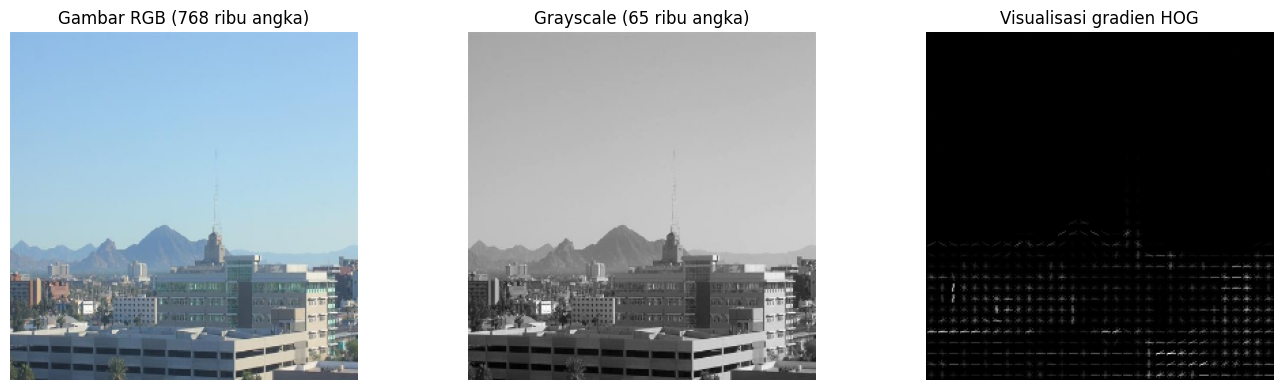

In [ ]:
# Visualisasi vektor HOG salah satu gambar (ilustrasi "yang dilihat model")
sample = X_test_img[0]
gray = cv2.cvtColor(sample, cv2.COLOR_RGB2GRAY)
_, hog_img = hog(gray, orientations=9, pixels_per_cell=(8, 8),
                 cells_per_block=(2, 2), block_norm='L2-Hys', visualize=True)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].imshow(sample); axes[0].set_title('Gambar RGB (768 ribu angka)')
axes[1].imshow(gray, cmap='gray'); axes[1].set_title('Grayscale (65 ribu angka)')
axes[2].imshow(hog_img, cmap='gray'); axes[2].set_title('Visualisasi gradien HOG')
for ax in axes: ax.axis('off')
plt.tight_layout(); plt.show()

## Langkah 5: Normalisasi Fitur

`StandardScaler` mengubah tiap dimensi fitur menjadi rata-rata 0 dan variansi 1, agar model tidak bias
pada fitur bernilai besar. Perhatikan `fit_transform` **hanya** pada data training; `scaler` inilah yang
nantinya disimpan sebagai `scaler.pkl`.

In [ ]:
# Normalize features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_feat)
X_test_scaled  = scaler.transform(X_test_feat)

print('Mean fitur setelah scaling (contoh 5 pertama):', X_train_scaled.mean(axis=0)[:5].round(4))
print('Std  fitur setelah scaling (contoh 5 pertama):', X_train_scaled.std(axis=0)[:5].round(4))

Mean fitur setelah scaling (contoh 5 pertama): [ 0.  0. -0.  0.  0.]
Std  fitur setelah scaling (contoh 5 pertama): [1. 1. 1. 1. 1.]


## Langkah 6: Split Data Training & Validation

20% data training dipakai sebagai *validation set* untuk memantau proses belajar (dan menjaga agar data
testing benar-benar tidak pernah dilihat saat training).

In [ ]:
# Split training data for validation
X_train, X_val, y_train, y_val = train_test_split(
    X_train_scaled, y_train,
    test_size=0.2,
    random_state=42
)

print('Train :', X_train.shape, '| Validation :', X_val.shape, '| Test :', X_test_scaled.shape)

Train : (192, 34596) | Validation : (48, 34596) | Test : (160, 34596)


## Langkah 7: Konversi Label ke Numpy Array

In [ ]:
# Convert labels to numpy arrays (required for Keras)
y_train = np.array(y_train)
y_val = np.array(y_val)
y_test = np.array(y_test)
print('y_train:', y_train.shape, y_train.dtype, '| y_val:', y_val.shape, '| y_test:', y_test.shape)

y_train: (192,) int64 | y_val: (48,) | y_test: (160,)


## Langkah 8: Membangun Arsitektur Model Neural Network

Jaringan *feedforward* 3 layer: input 34.596 fitur HOG → Dense 128 (ReLU) → Dense 64 (ReLU) →
Dense 1 (Sigmoid). Sigmoid + `binary_crossentropy` menghasilkan satu angka 0–1 = peluang "Day".

In [ ]:
input_dim = X_train.shape[1]

model = models.Sequential([
    layers.Input(shape=(input_dim,)),
    layers.Dense(128, activation='relu'),
    layers.Dense(64, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │     4,428,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,436,737 (16.92 MB)

 Trainable params: 4,436,737 (16.92 MB)

 Non-trainable params: 0 (0.00 B)

## Langkah 9: Training Model (20 epoch, batch size 32)

In [ ]:
history = model.fit(
    X_train, y_train,
    epochs=20,
    batch_size=32,
    validation_data=(X_val, y_val)
)

Epoch 1/20


1/6 ━━━━━━━━━━━━━━━━━━━━ 5s 1s/step - accuracy: 0.5000 - loss: 1.0622

3/6 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.6545 - loss: 0.9706

5/6 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 0.7058 - loss: 0.9733

6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 69ms/step - accuracy: 0.8333 - loss: 0.7768 - val_accuracy: 0.9375 - val_loss: 0.3085


...

Epoch 20/20


1/6 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step - accuracy: 1.0000 - loss: 4.0142e-06

3/6 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 1.0000 - loss: 2.7754e-06

5/6 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 1.0000 - loss: 2.7441e-06

6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - accuracy: 1.0000 - loss: 2.8368e-06 - val_accuracy: 0.9375 - val_loss: 0.6661


## Langkah 10: Evaluasi Model

In [ ]:
test_loss, test_acc = model.evaluate(X_test_scaled, y_test)
print("Loss Test     :", test_loss)
print("Akurasi Test  :", test_acc)

1/5 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 0.8125 - loss: 3.9177

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9312 - loss: 1.0905 


Loss Test     : 1.0905344486236572
Akurasi Test  : 0.9312499761581421


## Langkah 11: Prediksi, Classification Report, Confusion Matrix, dan Visualisasi

In [ ]:
y_pred_prob = model.predict(X_test_scaled, verbose=0)
y_pred = (y_pred_prob > 0.5).astype(int)

print(classification_report(y_test, y_pred, target_names=['night (0)', 'day (1)']))
cm = confusion_matrix(y_test, y_pred)
print('Confusion matrix:')
print(cm)

              precision    recall  f1-score   support

   night (0)       0.89      0.99      0.93        80
     day (1)       0.99      0.88      0.93        80

    accuracy                           0.93       160
   macro avg       0.94      0.93      0.93       160
weighted avg       0.94      0.93      0.93       160

Confusion matrix:
[[79  1]
 [10 70]]


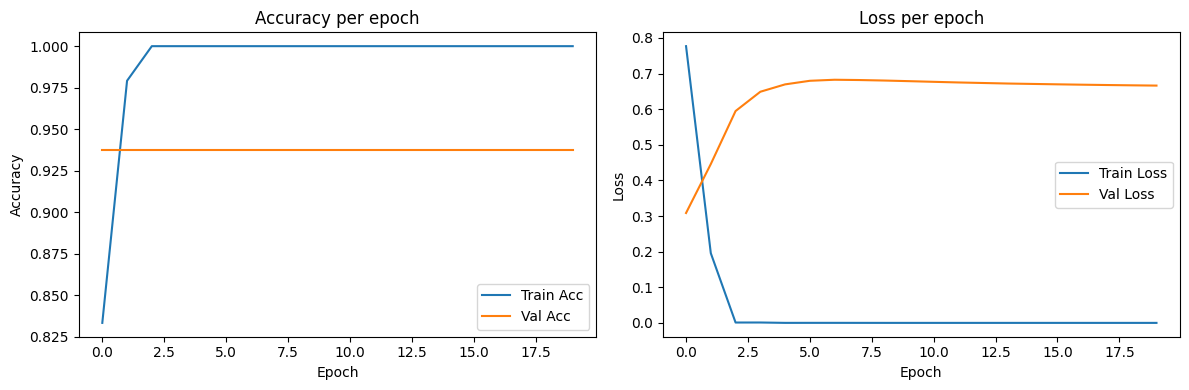

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history.history['accuracy'], label='Train Acc')
axes[0].plot(history.history['val_accuracy'], label='Val Acc')
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Accuracy')
axes[0].set_title('Accuracy per epoch'); axes[0].legend()
axes[1].plot(history.history['loss'], label='Train Loss')
axes[1].plot(history.history['val_loss'], label='Val Loss')
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Loss')
axes[1].set_title('Loss per epoch'); axes[1].legend()
plt.tight_layout(); plt.show()

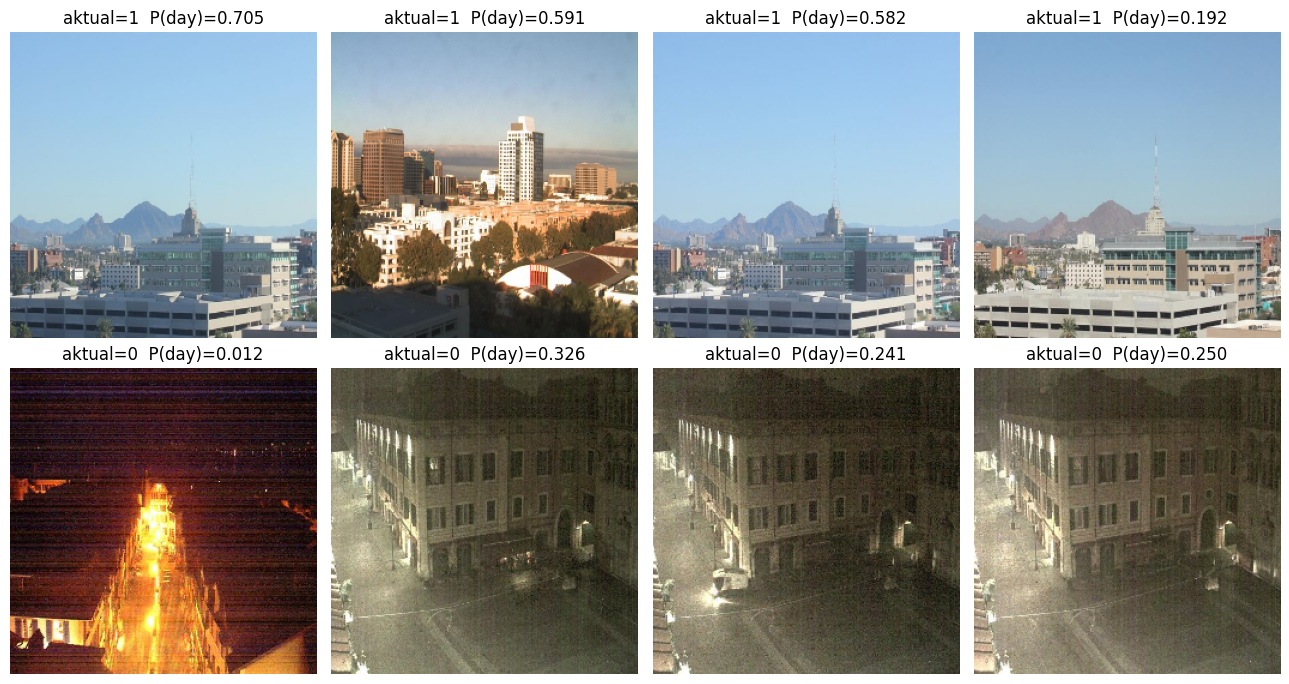

In [ ]:
# Contoh hasil prediksi pada beberapa gambar test
fig, axes = plt.subplots(2, 4, figsize=(13, 7))
for ax, i in zip(axes.ravel(), [0, 1, 2, 3, -4, -3, -2, -1]):
    img = X_test_img[i]
    score = model.predict(extract_hog([img]), verbose=0)[0][0]
    ax.imshow(img)
    ax.set_title(f"aktual={y_test[i]}  P(day)={score:.3f}")
    ax.axis('off')
plt.tight_layout(); plt.show()

## Langkah 12: Menyimpan Model dan Scaler (Artefak untuk Deployment)

Dua artefak ini yang akan "dibawa" ke Praktikum 2 — model `.h5` berisi bobot hasil belajar,
`scaler.pkl` berisi parameter normalisasi. Keduanya disimpan langsung ke folder proyek deployment.

> Peringatan `WARNING:absl: You are saving your model as an HDF5 file ... considered legacy` adalah hal normal
> pada Keras 3: modul ini memang mensyaratkan format `.h5` (dan `.h5` masih terbaca oleh `load_model`).
> Format yang dianjurkan Keras 3 sebenarnya `.keras`, namun keduanya sama-sama menyimpan arsitektur + bobot.
> Yang hilang dari `.h5` hanyalah state optimizer/metrics — tidak masalah untuk inference.

In [ ]:
import pickle

PROJECT_DIR = Path.cwd() / 'daynight-project'
PROJECT_DIR.mkdir(exist_ok=True)

model_path = PROJECT_DIR / 'day_night_model.h5'
scaler_path = PROJECT_DIR / 'scaler.pkl'

# 1. Simpan Model (format .h5)
model.save(str(model_path))
print('Model  berhasil disimpan :', model_path, f'({model_path.stat().st_size/1024/1024:.2f} MB)')

# 2. Simpan Scaler
with open(scaler_path, 'wb') as f:
    pickle.dump(scaler, f)
print('Scaler berhasil disimpan :', scaler_path, f'({scaler_path.stat().st_size/1024:.1f} KB)')

print('\nTotal parameter model   :', model.count_params())

Model  berhasil disimpan : D:\KULIAH\SMT-5\Machine Learning\erilocshada-machine-learning-course\daynight-project\day_night_model.h5 (50.80 MB)
Scaler berhasil disimpan : D:\KULIAH\SMT-5\Machine Learning\erilocshada-machine-learning-course\daynight-project\scaler.pkl (811.3 KB)

Total parameter model   : 4436737


---
# Praktikum 2 — Deployment ke Hugging Face (Docker + Flask)

Siklus MLOps sederhana: model yang sudah dilatih **dibungkus sebagai layanan web** (microservice) yang bisa
diakses pengguna lewat browser. Tiga berkas dibuat di folder `daynight-project/`:

```
daynight-project/
├── app.py               # Flask: form upload + endpoint /predict  (real-time inference)
├── requirements.txt     # library Python yang dibutuhkan container
├── Dockerfile           # resep image: OS minimal + library sistem + kode + model
├── day_night_model.h5   # artefak hasil Langkah 12
└── scaler.pkl           # artefak hasil Langkah 12
```

## Langkah 1: Persiapan Environment & Menulis Berkas Proyek

Berkas `app.py`, `requirements.txt`, dan `Dockerfile` ditulis dari notebook ini supaya isinya selalu sama
dan mudah direproduksi. Tiga konstanta di bawah adalah isi lengkap tiap berkas.

In [ ]:
APP_PY_SRC = 'import os\nimport numpy as np\nimport cv2\nimport pickle\nimport tensorflow as tf\nfrom flask import Flask, request, render_template_string\nfrom skimage.feature import hog\n\napp = Flask(__name__)\n\n# Artefak diletakkan di samping file ini (di Hugging Face: /app)\nBASE_DIR = os.path.dirname(os.path.abspath(__file__))\nMODEL_PATH = os.path.join(BASE_DIR, \'day_night_model.h5\')\nSCALER_PATH = os.path.join(BASE_DIR, \'scaler.pkl\')\n\ntry:\n    # compile=False: untuk inference kita hanya butuh arsitektur + bobot,\n    # bukan optimizer/loss yang dipakai saat training.\n    model = tf.keras.models.load_model(MODEL_PATH, compile=False)\n    with open(SCALER_PATH, \'rb\') as f:\n        scaler = pickle.load(f)\n    print("System Loaded Successfully")\nexcept Exception as e:\n    print(f"Error loading system: {e}")\n\n\ndef preprocess_image(image_bytes):\n    nparr = np.frombuffer(image_bytes, np.uint8)\n    img = cv2.imdecode(nparr, cv2.IMREAD_COLOR)\n    if img is None:\n        raise ValueError("Gambar tidak dapat dibaca")\n\n    # Harus sama persis dengan preprocessing saat training\n    img = cv2.resize(img, (256, 256))\n    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)\n    hog_feat = hog(gray, orientations=9, pixels_per_cell=(8, 8),\n                   cells_per_block=(2, 2), block_norm=\'L2-Hys\',\n                   visualize=False, feature_vector=True)\n    return scaler.transform(hog_feat.reshape(1, -1))\n\n\n@app.route(\'/\', methods=[\'GET\'])\ndef home():\n    return render_template_string(\'\'\'\n    <div style="text-align:center; padding:50px;">\n        <h1>Day vs Night Classifier</h1>\n        <form action="/predict" method="post" enctype="multipart/form-data">\n            <input type="file" name="file" required><br><br>\n            <button type="submit">Prediksi</button>\n        </form>\n    </div>\n    \'\'\')\n\n\n@app.route(\'/predict\', methods=[\'POST\'])\ndef predict():\n    try:\n        file = request.files[\'file\']\n        data = preprocess_image(file.read())\n        prediction = model.predict(data)[0][0]\n        label = "Day (Siang)" if prediction > 0.5 else "Night (Malam)"\n        return (f"<h2 style=\'text-align:center\'>Hasil: {label}</h2>"\n                f"<p style=\'text-align:center\'>Skor: {prediction:.4f}</p>"\n                f"<center><a href=\'/\'>Kembali</a></center>")\n    except Exception as e:\n        return f"Error: {e}"\n\n\nif __name__ == \'__main__\':\n    # Port 7860 wajib untuk Hugging Face Spaces\n    app.run(host=\'0.0.0.0\', port=7860)\n'
REQUIREMENTS_SRC = 'flask\ntensorflow-cpu\nnumpy\nscikit-learn\nscikit-image\nopencv-python-headless\ngunicorn\n'
DOCKERFILE_SRC = '# Base Image Python 3.9 Slim\nFROM python:3.9-slim\n\n# Install Library Sistem untuk OpenCV (Debian Bookworm/Trixie Compatible)\nRUN apt-get update && apt-get install -y \\\n    libgl1 \\\n    libglib2.0-0 \\\n    && rm -rf /var/lib/apt/lists/*\n\n# Setup User Non-Root (Standar Keamanan HF)\nRUN useradd -m -u 1000 user\nUSER user\nENV PATH="/home/user/.local/bin:$PATH"\n\n# Setup Direktori Kerja\nWORKDIR /app\n\n# Install Dependencies\nCOPY --chown=user ./requirements.txt requirements.txt\nRUN pip install --no-cache-dir --upgrade -r requirements.txt\n\n# Copy File Aplikasi\nCOPY --chown=user . /app\n\n# Expose Port & Jalankan\nEXPOSE 7860\nCMD ["python", "app.py"]\n'

Menulis berkas ke folder `daynight-project/` dan menampilkannya kembali:

In [ ]:
# newline LF eksplisit: Dockerfile dengan line ending CRLF berisiko membuat instruksi Docker salah parse
for nama, isi in [('app.py', APP_PY_SRC), ('requirements.txt', REQUIREMENTS_SRC), ('Dockerfile', DOCKERFILE_SRC)]:
    with open(PROJECT_DIR / nama, 'w', encoding='utf-8', newline='\n') as f:
        f.write(isi)

for f in sorted(PROJECT_DIR.iterdir()):
    print(f'{f.name:22s} {f.stat().st_size/1024:8.1f} KB')

app.py                      2.4 KB
day_night_model.h5      52020.7 KB
Dockerfile                  0.6 KB
README.md                   1.7 KB
requirements.txt            0.1 KB
scaler.pkl                811.3 KB


In [ ]:
print('=' * 78)
print('app.py')
print('=' * 78)
print((PROJECT_DIR / 'app.py').read_text(encoding='utf-8'))

app.py
import os
import numpy as np
import cv2
import pickle
import tensorflow as tf
from flask import Flask, request, render_template_string
from skimage.feature import hog

app = Flask(__name__)

# Artefak diletakkan di samping file ini (di Hugging Face: /app)
BASE_DIR = os.path.dirname(os.path.abspath(__file__))
MODEL_PATH = os.path.join(BASE_DIR, 'day_night_model.h5')
SCALER_PATH = os.path.join(BASE_DIR, 'scaler.pkl')

try:
    # compile=False: untuk inference kita hanya butuh arsitektur + bobot,
    # bukan optimizer/loss yang dipakai saat training.
    model = tf.keras.models.load_model(MODEL_PATH, compile=False)
    with open(SCALER_PATH, 'rb') as f:
        scaler = pickle.load(f)
    print("System Loaded Successfully")
except Exception as e:
    print(f"Error loading system: {e}")


def preprocess_image(image_bytes):
    nparr = np.frombuffer(image_bytes, np.uint8)
    img = cv2.imdecode(nparr, cv2.IMREAD_COLOR)
    if img is None:
        raise ValueError("Gambar tidak dapat 

In [ ]:
print('=' * 78); print('requirements.txt'); print('=' * 78)
print((PROJECT_DIR / 'requirements.txt').read_text(encoding='utf-8'))
print('=' * 78); print('Dockerfile'); print('=' * 78)
print((PROJECT_DIR / 'Dockerfile').read_text(encoding='utf-8'))

requirements.txt
flask
tensorflow-cpu
numpy
scikit-learn
scikit-image
opencv-python-headless
gunicorn

Dockerfile
# Base Image Python 3.9 Slim
FROM python:3.9-slim

# Install Library Sistem untuk OpenCV (Debian Bookworm/Trixie Compatible)
RUN apt-get update && apt-get install -y \
    libgl1 \
    libglib2.0-0 \
    && rm -rf /var/lib/apt/lists/*

# Setup User Non-Root (Standar Keamanan HF)
RUN useradd -m -u 1000 user
USER user
ENV PATH="/home/user/.local/bin:$PATH"

# Setup Direktori Kerja
WORKDIR /app

# Install Dependencies
COPY --chown=user ./requirements.txt requirements.txt
RUN pip install --no-cache-dir --upgrade -r requirements.txt

# Copy File Aplikasi
COPY --chown=user . /app

# Expose Port & Jalankan
EXPOSE 7860
CMD ["python", "app.py"]



**Poin penting di dalam berkas-berkas tersebut**

- `app.py`: preprocessing pada jalur inference (`resize 256×256` → grayscale → HOG dengan parameter identik →
  `scaler.transform`) **harus sama persis** dengan training; kalau beda, akurasi di production runtuh.
  Aplikasi mendengarkan di `0.0.0.0:7860` — port wajib Hugging Face Spaces.
  Model dimuat dengan `load_model(..., compile=False)` karena layanan ini hanya melakukan inference:
  optimizer/loss hasil training tidak diperlukan (dan format `.h5` warisan Keras memang tidak menyimpannya
  secara lengkap), yang dibutuhkan hanya arsitektur + bobot.
- `requirements.txt`: memakai `tensorflow-cpu` (container HF tier gratis tidak punya GPU) dan
  `opencv-python-headless` (tanpa GUI, tidak butuh display).
- `Dockerfile`: `libgl1` & `libglib2.0-0` di-install karena OpenCV gagal impor tanpa library sistem itu;
  `useradd -m -u 1000 user` + `USER user` karena Hugging Face mewajibkan container berjalan sebagai non-root.

## Langkah 2: Menguji Aplikasi Secara Lokal (sebelum di-push)

Sebelum naik ke cloud, dua endpoint diuji memakai Flask *test client* — ini memastikan berkas model & scaler
cocok dengan kode inference. (Jika ingin menguji lewat browser: `python app.py` lalu buka
`http://localhost:7860`.)

In [ ]:
import importlib.util, io, re

spec = importlib.util.spec_from_file_location('daynight_app', PROJECT_DIR / 'app.py')
daynight_app = importlib.util.module_from_spec(spec)
spec.loader.exec_module(daynight_app)

client = daynight_app.app.test_client()

resp_home = client.get('/')
print('GET  /        -> status', resp_home.status_code,
      '| form tampil:', b'Day vs Night Classifier' in resp_home.data)

# POST /predict dengan gambar day dan night dari data testing
for label_name, idx in [('day', int(np.where(y_test == 1)[0][0])),
                        ('night', int(np.where(y_test == 0)[0][0]))]:
    img = cv2.cvtColor(X_test_img[idx], cv2.COLOR_RGB2BGR)
    ok, buf = cv2.imencode('.jpg', img)
    resp = client.post('/predict', data={'file': (io.BytesIO(buf.tobytes()), 'sample.jpg')},
                       content_type='multipart/form-data')
    teks = re.sub(r'\s+', ' ', re.sub(r'<[^>]+>', ' ', resp.data.decode('utf-8', 'ignore'))).strip()
    print(f'POST /predict (gambar {label_name:5s}) -> status', resp.status_code, '|', teks)

System Loaded Successfully
GET  /        -> status 200 | form tampil: True
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 91ms/step


POST /predict (gambar day  ) -> status 200 | Hasil: Day (Siang) Skor: 1.0000 Kembali
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step


POST /predict (gambar night) -> status 200 | Hasil: Night (Malam) Skor: 0.0000 Kembali


## Langkah 3: Setup Hugging Face Space (manual di browser)

1. Login ke [huggingface.co](https://huggingface.co/) → foto profil → **New Space**.
2. Isi: **Space Name** `daynight-classifier-244107020064`, **License** Apache-2.0/MIT,
   **SDK** = `Docker`, **Template** dikosongkan, **Visibility** = Public → **Create Space**.
3. **Settings → Access Tokens → New token**, permission **Write**, lalu salin token (hanya tampil sekali).

## Langkah 4: Upload ke Cloud dengan Git CLI

```bash
git clone https://huggingface.co/spaces/USERNAME_ANDA/NAMA_SPACE
# salin app.py, Dockerfile, requirements.txt, day_night_model.h5, scaler.pkl ke folder hasil clone
cd NAMA_SPACE
git add .
git commit -m "Deploy aplikasi ke HF"
git push
# Username  = username Hugging Face
# Password  = Access Token (BUKAN password akun)
```

## Langkah 5: Pengujian dan Hasil Akhir

Buka halaman Space → tab **App** → status **Building** (biru, ±3–5 menit karena image Docker dibangun
dari nol) → **Running** (hijau). Upload gambar siang/malam, pastikan label prediksi sesuai.

---
# Rangkuman & Refleksi

**Arsitektur deployment yang dipraktikkan:** *server-side real-time inference* dalam bentuk microservice
(model dibungkus layanan terpisah, diakses lewat API), bukan *batch processing* (prediksi massal terjadwal)
dan bukan *edge/mobile* (model ditanam di perangkat, butuh konversi `.tflite`/ONNX).

| Perspektif | Pilihan di modul ini | Konsekuensi |
|---|---|---|
| Arsitektur | microservice (model = layanan sendiri) | update model tanpa mematikan aplikasi utama |
| Infrastruktur | Docker container di Hugging Face Spaces | bebas *dependency hell*, perilaku identik di mana pun |
| Serving | real-time via Flask | *latency* jadi ukuran keberhasilan |
| Strategi | web (server-side) | butuh internet, tapi komputasi kuat & kode model tidak terkirim ke pengguna |

**Hal yang paling sering keliru saat deploy:**
1. Lupa membawa `scaler.pkl`, atau memakai `fit_transform` (bukan `transform`) pada data inference.
2. Parameter HOG di `app.py` tidak identik dengan saat training → fitur berubah dimensi/interpretasi.
3. Container memakai root user (ditolak HF) atau kekurangan `libgl1`/`libglib2.0-0` (OpenCV gagal impor).
4. Port salah — Hugging Face Spaces Docker mengharuskan aplikasi mendengarkan **7860**.

**Bagian Tugas** (menerapkan pipeline yang sama pada proyek pribadi) **tidak dikerjakan** sesuai instruksi;
langkahnya sudah tercatat pada Praktikum 2 dan siap dipakai sebagai template.